In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/soil-grain-size-from-photos/sample_submission.csv
/kaggle/input/competitions/soil-grain-size-from-photos/Training_labels_updated.csv
/kaggle/input/competitions/soil-grain-size-from-photos/ppm_updated.csv
/kaggle/input/competitions/soil-grain-size-from-photos/Training-All_Photos_updated/Training-All_Photos_updated/Samsung_A52_H666_01.jpg
/kaggle/input/competitions/soil-grain-size-from-photos/Training-All_Photos_updated/Training-All_Photos_updated/Motorola_Edge_60_fusion_H374_02.jpg
/kaggle/input/competitions/soil-grain-size-from-photos/Training-All_Photos_updated/Training-All_Photos_updated/Motorola_Edge_60_fusion_H374_03.jpg
/kaggle/input/competitions/soil-grain-size-from-photos/Training-All_Photos_updated/Training-All_Photos_updated/Motorola_Edge_H368_04.jpg
/kaggle/input/competitions/soil-grain-size-from-photos/Training-All_Photos_updated/Training-All_Photos_updated/Samsung_A52_H038_01.jpg
/kaggle/input/competitions/soil-grain-size-from-photos/Training-All_

In [2]:
import os

DATA = "/kaggle/input/competitions/soil-grain-size-from-photos"

print("DATA exists:", os.path.exists(DATA))
print(os.listdir(DATA)[:20])

DATA exists: True
['sample_submission.csv', 'Training_labels_updated.csv', 'Training-All_Photos_updated', 'ppm_updated.csv', 'Test_All_Photos']


train photos 127 / 24 samples | test photos 35 / 10 samples


config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

loaded backbone dino facebook/dinov2-base


...

pytorch_model.bin:   0%|          | 0.00/599M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/599M [00:00<?, ?B/s]

CLIPVisionModel LOAD REPORT from: openai/clip-vit-base-patch16
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.embeddings.position_embedding.weight              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight    

loaded backbone clip openai/clip-vit-base-patch16
  train 0/127  (5s)
  train 10/127  (36s)
  train 20/127  (66s)
  train 30/127  (96s)
  train 40/127  (126s)
  train 50/127  (156s)
  train 60/127  (186s)
  train 70/127  (216s)
  train 80/127  (247s)
  train 90/127  (278s)
  train 100/127  (309s)
  train 110/127  (339s)
  train 120/127  (370s)
  test 0/35  (1s)
  test 10/35  (13s)
  test 20/35  (26s)
  test 30/35  (40s)
feature blocks: {'dino_rgb': 3072, 'dino_gray': 3072, 'clip_rgb': 3072, 'clip_gray': 3072, 'spec': 29} | train rows 381 | test rows 35
feature sets: ['spec', 'dino', 'dino_gray', 'clip', 'dino+spec', 'gray+spec', 'all']
  cv 0/114 (0s)
  cv 10/114 (1s)
  cv 20/114 (40s)
  cv 30/114 (66s)
  cv 40/114 (105s)
  cv 50/114 (141s)
  cv 60/114 (158s)
  cv 70/114 (208s)
  cv 80/114 (244s)
  cv 90/114 (280s)
  cv 100/114 (339s)
  cv 110/114 (387s)

Top 15 single configurations (lower is better):
                      config  LOSO   FAM   obj
           gray+spec|knn|k=3 36.86 44

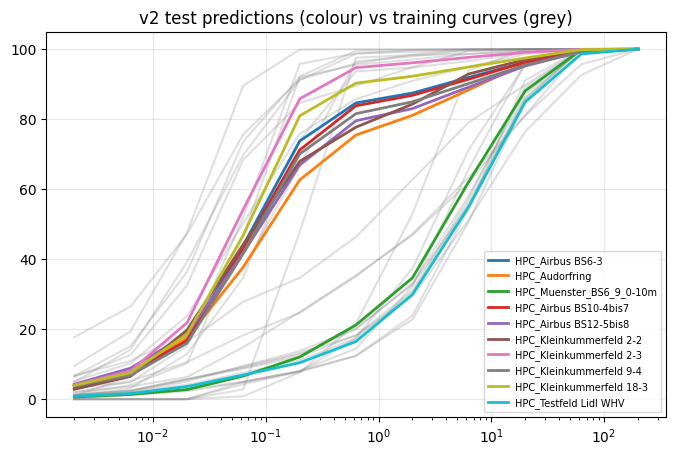

In [3]:
# Soil grain size from photos: pipeline v2  (Kaggle notebook, paste cell by cell at each "# %%")
#
# What is new compared with v1 (every piece is switchable and judged by cross-validation, not by belief):
#   * two frozen backbones (DINOv2 + CLIP), each on an RGB view and a colour-free (gray) view
#   * physical "scale spectrum": radial FFT power in log-spaced bands, in units of mm (uses ppm)
#   * domain randomisation for the train->iPhone shift: extra augmented copies of every training photo
#     (scale jitter +-15%, gamma / contrast / colour cast, blur, noise) + random rotations/flips
#   * model zoo: ridge, reduced-rank ridge, kernel ridge, kNN over training soils, and a linear head trained
#     DIRECTLY on the EMD metric with softmax->cumsum (valid curves by construction)
#   * sample-balanced weights (a sample with 8 photos does not outweigh one with 3)
#   * two validations: leave-one-sample-out AND leave-one-camera-family-out (the closer proxy for iPhone test data)
#   * Caruana ensemble selection on both, including "constant curve" candidates so the ensemble can shrink safely
#
# Needs a GPU (T4 is fine) and internet for the backbones. EMBED_BACKEND=stub / FAST=1 are debugging switches.

# %% 1. Config
import os, re, glob, unicodedata, warnings, time, collections, contextlib
import numpy as np, pandas as pd, cv2
from PIL import Image, ImageOps
warnings.filterwarnings("ignore")
Image.MAX_IMAGE_PIXELS = None

DATA = os.environ.get("DATA_DIR", "/kaggle/input/competitions/soil-grain-size-from-photos")
OUT = os.environ.get("OUT_DIR", "/kaggle/working")
BACKEND = os.environ.get("EMBED_BACKEND", "real")     # "stub" = random features, only to debug the code
FAST = int(os.environ.get("FAST", "0"))               # 1 = tiny grids / few crops, for a quick smoke test
BACKBONES = {"dino": ("dinov2", "facebook/dinov2-base"), "clip": ("clip", "openai/clip-vit-base-patch16")}
IMNET = ([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
CLIPN = ([0.4815, 0.4578, 0.4082], [0.2686, 0.2613, 0.2758])
TARGET_PPM = 4.5            # common physical scale, px per mm
CROP = 448                  # 448 px = ~100 mm field of view at 4.5 px/mm
N_CROPS = 6 if FAST else 16
N_AUG = 1 if FAST else 2    # augmented copies per TRAINING photo (test photos are never augmented)
W_FAM = 0.5                 # weight of the camera-family CV in model selection (LOSO gets 1 - W_FAM)
SEED = 0
BINS = np.array([0.002, 0.0063, 0.02, 0.063, 0.2, 0.63, 2.0, 6.3, 20, 63, 200])
W = np.diff(np.log10(BINS))
os.makedirs(OUT, exist_ok=True)

def emd(y, p):
    """Area between the curves on a log-x axis (trapezoid). Assumed form of the competition metric."""
    d = np.abs(np.atleast_2d(y) - np.atleast_2d(p))
    return (0.5 * (d[:, :-1] + d[:, 1:]) * W).sum(1)

def fix(c):
    c = np.clip(np.asarray(c, float), 0, 100)
    c = np.maximum.accumulate(c, axis=-1)
    c[..., -1] = 100.0
    return c

# %% 2. Tables (same logic as v1)
lab = pd.read_csv(f"{DATA}/Training_labels_updated.csv")
sub = pd.read_csv(f"{DATA}/sample_submission.csv")
ppm_tab = pd.read_csv(f"{DATA}/ppm_updated.csv").set_index("phone")
tcols = sorted([c for c in lab.columns if c != "sample_id"], key=float)
assert [float(c) for c in tcols] == list(BINS) and [float(c) for c in sub.columns[1:]] == list(BINS)
lab["sample_id"] = lab["sample_id"].astype(str)
lab = lab.set_index("sample_id")

def norm_name(s):
    s = unicodedata.normalize("NFC", s)
    for a, b in [("ü", "ue"), ("ö", "oe"), ("ä", "ae"), ("ß", "ss"), (",", "_")]:
        s = s.replace(a, b)
    return s

def device(fname):
    f = fname.lower().replace(" ", "_")
    if "samsung" in f: return "Samsung A52"
    if "fusion" in f: return "Motorola Edge 60 Fusion"
    if "motorola" in f: return "Motorola Edge"
    if "iphone_16" in f or "iphone16" in f: return "iPhone 16"
    if "iphone_14" in f or "iphone14" in f: return "iPhone 14"
    raise ValueError(f"unknown device: {fname}")

def train_id(fname):
    return re.search(r"_([A-Z]\d{3})_\d+\.\w+$", fname, re.I).group(1).upper()

def test_id(fname):
    return norm_name(re.match(r"^iphone_?1[46]_(HPC_.+?)(?: \(\d+\))?\.jpe?g$", fname, re.I).group(1))

def photos(folder, id_fn):
    fs = sorted(f for f in glob.glob(f"{DATA}/{folder}/**/*", recursive=True) if f.lower().endswith((".jpg", ".jpeg", ".png")))
    return pd.DataFrame({"path": fs, "sid": [id_fn(os.path.basename(f)) for f in fs],
                         "device": [device(os.path.basename(f)) for f in fs]})

tr = photos("Training-All_Photos_updated", train_id)
te = photos("Test_All_Photos", test_id)
assert set(tr.sid) == set(lab.index) and set(te.sid) == set(sub.sample_id)
print(f"train photos {len(tr)} / {tr.sid.nunique()} samples | test photos {len(te)} / {te.sid.nunique()} samples")

def eff_ppm(dev, w, h):
    r = ppm_tab.loc[dev]
    return r.ppm * max(w, h) / max(r.width, r.height)

# %% 3. Image handling: physical scale, crops, augmentation, features that do not need a network
def load_raw(path):
    return ImageOps.exif_transpose(Image.open(path)).convert("RGB")

def to_scale(im, dev, ppm_target):
    w, h = im.size
    s = ppm_target / eff_ppm(dev, w, h)
    if abs(s - 1) > 0.02:
        im = im.resize((max(1, round(w * s)), max(1, round(h * s))), Image.LANCZOS)
    return np.asarray(im)

def sample_crops(a, rng, n, size=CROP):
    H, Wd = a.shape[:2]
    size = min(size, int(0.9 * min(H, Wd)))
    x0, x1 = int(0.10 * Wd), max(int(0.90 * Wd) - size, int(0.10 * Wd))
    y0, y1 = int(0.20 * H), max(int(0.90 * H) - size, int(0.20 * H))
    out = []
    for _ in range(n):
        x = min(int(rng.integers(x0, x1 + 1)), Wd - size)
        y = min(int(rng.integers(y0, y1 + 1)), H - size)
        c = np.rot90(a[y:y + size, x:x + size], int(rng.integers(4)))   # soil has no "up": random dihedral view
        if rng.random() < 0.5: c = c[:, ::-1]
        out.append(np.ascontiguousarray(c))
    return out

def augment(c, rng):
    """Cheap 'other camera' simulation: gamma, contrast/brightness, colour cast, blur, sensor noise."""
    x = c.astype(np.float32) / 255
    x = x ** rng.uniform(0.75, 1.3)
    x = (x - 0.5) * rng.uniform(0.8, 1.25) + 0.5 + rng.uniform(-0.08, 0.08)
    x = x * rng.uniform(0.92, 1.08, (1, 1, 3))
    s = rng.uniform(0, 1.2)
    if s > 0.3: x = cv2.GaussianBlur(x, (0, 0), s)
    x = x + rng.normal(0, rng.uniform(0, 0.02), x.shape).astype(np.float32)
    return (np.clip(x, 0, 1) * 255).astype(np.uint8)

def to224(c):
    return np.asarray(Image.fromarray(c).resize((224, 224), Image.LANCZOS))

def center224(c):          # native scale, 224 px = ~50 mm
    m = max((c.shape[0] - 224) // 2, 0)
    return to224(c[m:m + 224, m:m + 224])

def gray_view(c):          # colour-free view: per-crop standardised luminance, replicated to 3 channels
    g = c.astype(np.float32).mean(-1)
    g = np.clip((g - g.mean()) / (g.std() + 1e-6) * 0.2 + 0.5, 0, 1)
    return np.repeat((g * 255).astype(np.uint8)[..., None], 3, -1)

_RING = {}
def spectrum(c, nb=14):
    """Radial power spectrum in log-spaced bands from 2 px to n/2 px wavelength (= ~0.4 mm ... 50 mm at 4.5 px/mm)."""
    n = min(c.shape[:2]); c = c[:n, :n]
    if (n, nb) not in _RING:
        f = np.fft.fftfreq(n); rr = np.sqrt(f[:, None] ** 2 + f[None, :] ** 2)
        edges = np.geomspace(1.0 / (n / 2), 0.5, nb + 1)
        idx = np.digitize(rr, edges) - 1; idx[(idx < 0) | (idx >= nb)] = -1
        _RING[(n, nb)] = (idx, np.outer(np.hanning(n), np.hanning(n)).astype(np.float32), np.log(np.sqrt(edges[:-1] * edges[1:])))
    idx, win, lf = _RING[(n, nb)]
    g = c.astype(np.float32).mean(-1); g = (g - g.mean()) / (g.std() + 1e-6)
    P = np.abs(np.fft.fft2(g * win)) ** 2
    m = idx >= 0
    b = np.log(np.bincount(idx[m], P[m], nb) / np.maximum(np.bincount(idx[m], minlength=nb), 1) + 1e-6)
    return np.concatenate([b, b - b.mean(), [np.polyfit(lf, b, 1)[0]]])

# %% 4. Backbones (frozen)
def _torch_embedder(model, kind, norm, dv):
    import torch
    mean = torch.tensor(norm[0], device=dv).view(1, 3, 1, 1); std = torch.tensor(norm[1], device=dv).view(1, 3, 1, 1)
    @torch.no_grad()
    def emb(crops):
        outs = []
        for i in range(0, len(crops), 64):
            x = torch.from_numpy(np.stack(crops[i:i + 64])).to(dv).permute(0, 3, 1, 2).float() / 255
            ctx = torch.autocast("cuda", dtype=torch.float16) if dv == "cuda" else contextlib.nullcontext()
            with ctx:
                o = model(pixel_values=(x - mean) / std)
            h = o.last_hidden_state
            cls = o.pooler_output if kind == "clip" else h[:, 0]
            outs.append(torch.cat([cls, h[:, 1:].mean(1)], 1).float().cpu().numpy())
        return np.concatenate(outs)
    return emb

def make_embedders():
    if BACKEND == "stub":
        out = {}
        for k, seed in [("dino", 1), ("clip", 2)]:
            proj = np.random.default_rng(seed).standard_normal((192, 48)).astype(np.float32)
            out[k] = lambda crops, proj=proj: (np.stack([cv2.resize(c, (8, 8), interpolation=cv2.INTER_AREA) for c in crops])
                                                .reshape(len(crops), -1).astype(np.float32) / 255 - .5) @ proj
        return out
    import torch
    from transformers import AutoModel, CLIPVisionModel
    dv = "cuda" if torch.cuda.is_available() else "cpu"
    if dv == "cpu": print("!! no GPU: this will be slow")
    out = {}
    for key, (kind, mid) in BACKBONES.items():
        try:
            model = (CLIPVisionModel if kind == "clip" else AutoModel).from_pretrained(mid).to(dv).eval()
            out[key] = _torch_embedder(model, kind, CLIPN if kind == "clip" else IMNET, dv)
            print("loaded backbone", key, mid)
        except Exception as e:
            print(f"!! backbone {key} unavailable ({type(e).__name__}: {str(e)[:80]}) -> skipped")
    assert out, "no backbone could be loaded (internet off? add a model via Add Input > Models)"
    return out

embedders = make_embedders()

def extract(df, tag, n_aug):
    cache = f"{OUT}/feats2_{tag}_{BACKEND}_{N_CROPS}_{n_aug}_{'-'.join(embedders)}.npz"
    if os.path.exists(cache):
        z = np.load(cache, allow_pickle=True)
        if list(z["paths"]) == list(df.path):
            print("loaded cache", cache)
            return z["meta"], {k[2:]: z[k] for k in z.files if k.startswith("B_")}
    rng = np.random.default_rng(SEED)
    meta, blocks = [], collections.defaultdict(list)
    t0 = time.time()
    for i, r in enumerate(df.itertuples()):
        im = load_raw(r.path)
        for v in range(1 + n_aug):                        # v = 0 clean, v >= 1 augmented (training only)
            a = to_scale(im, r.device, TARGET_PPM if v == 0 else TARGET_PPM * rng.uniform(0.85, 1.15))
            cs = sample_crops(a, rng, N_CROPS)
            if v > 0: cs = [augment(c, rng) for c in cs]
            fine, coarse = [center224(c) for c in cs], [to224(c) for c in cs]
            for name, emb in embedders.items():
                for view, tf in (("rgb", lambda x: x), ("gray", gray_view)):
                    e = emb([tf(x) for x in fine + coarse])
                    blocks[f"{name}_{view}"].append(np.concatenate([e[:N_CROPS].mean(0), e[N_CROPS:].mean(0)]))
            blocks["spec"].append(np.mean([spectrum(c) for c in cs], 0))
            meta.append((i, v))
        if i % 10 == 0: print(f"  {tag} {i}/{len(df)}  ({time.time() - t0:.0f}s)")
    meta = np.array(meta); blocks = {k: np.stack(v) for k, v in blocks.items()}
    np.savez(cache, paths=np.array(df.path), meta=meta, **{f"B_{k}": v for k, v in blocks.items()})
    return meta, blocks

meta_tr, B_tr = extract(tr, "train", N_AUG)
meta_te, B_te = extract(te, "test", 0)
R = tr.iloc[meta_tr[:, 0]].reset_index(drop=True); R["view"] = meta_tr[:, 1]
Rte = te.iloc[meta_te[:, 0]].reset_index(drop=True)
print("feature blocks:", {k: v.shape[1] for k, v in B_tr.items()}, "| train rows", len(R), "| test rows", len(Rte))

# %% 5. Feature sets, targets, folds
sids = sorted(tr.sid.unique())
Yrows = lab.loc[R.sid, tcols].values.astype(float)
Ys = lab.loc[sids, tcols].values.astype(float)
fam_row = np.where(R.device.str.startswith("Motorola"), "Motorola", R.device).astype(str)
fam_of = {s: pd.Series(fam_row[R.sid.values == s]).mode()[0] for s in sids}
g_all = R.sid.values
clean_rows = {s: np.where((g_all == s) & (R.view.values == 0))[0] for s in sids}

SETS_DEF = {                      # name -> [(block, weight)]
    "spec":      [("spec", 1)],
    "dino":      [("dino_rgb", 1)],
    "dino_gray": [("dino_gray", 1)],
    "clip":      [("clip_rgb", 1)],
    "dino+spec": [("dino_rgb", 1), ("spec", 1)],
    "gray+spec": [("dino_gray", 1), ("clip_gray", 1), ("spec", 1)],
    "all":       [("dino_rgb", 1), ("dino_gray", 1), ("clip_rgb", 1), ("clip_gray", 1), ("spec", 1.5)],
}
SETS = {}
for name, parts in SETS_DEF.items():
    if all(b in B_tr for b, _ in parts):
        SETS[name] = dict(Xtr=np.hstack([B_tr[b] for b, _ in parts]), Xte=np.hstack([B_te[b] for b, _ in parts]),
                          spec=([B_tr[b].shape[1] for b, _ in parts], [w for _, w in parts]))
print("feature sets:", list(SETS))

def sample_weights(g):
    _, inv, cnt = np.unique(g, return_inverse=True, return_counts=True)
    w = 1.0 / cnt[inv]
    return w * len(w) / w.sum()

# %% 6. Models
class Base:
    def __init__(self, spec, **kw): self.spec, self.kw = spec, kw
    def _fit_scale(self, X):
        sizes, wts = self.spec
        self.mu, self.sd = X.mean(0), X.std(0) + 1e-6
        self.wv = np.repeat(np.asarray(wts, float) / np.sqrt(sizes), sizes)
        return self._scale(X)
    def _scale(self, X): return (X - self.mu) / self.sd * self.wv

def _add100(P): return np.hstack([P, np.full((len(P), 1), 100.0)])

class RidgeM(Base):
    def fit(self, X, Y, g):
        from sklearn.linear_model import Ridge
        Xs, sw = self._fit_scale(X), sample_weights(g)
        self.m = Ridge(alpha=self.kw["a"] * len(X)).fit(Xs, Y[:, :-1], sample_weight=sw)
        r = self.kw.get("r")
        if r:                                            # reduced rank: keep the r main "curve shapes"
            self.mu_y = np.average(Y[:, :-1], 0, sw)
            self.V = np.linalg.svd((Y[:, :-1] - self.mu_y) * np.sqrt(sw)[:, None], full_matrices=False)[2][:r]
        return self
    def predict(self, X):
        P = self.m.predict(self._scale(X))
        if self.kw.get("r"): P = self.mu_y + (P - self.mu_y) @ self.V.T @ self.V
        return _add100(P)

class KRR(Base):
    def fit(self, X, Y, g):
        from sklearn.metrics.pairwise import euclidean_distances
        self.Xs, sw = self._fit_scale(X), sample_weights(g)
        d2 = euclidean_distances(self.Xs, squared=True)
        self.gam = 1.0 / np.median(d2[d2 > 0])
        K = np.exp(-self.gam * d2)
        self.mu_y = np.average(Y[:, :-1], 0, sw)
        self.c = np.linalg.solve(K + self.kw["a"] * np.diag(1.0 / sw), Y[:, :-1] - self.mu_y)
        return self
    def predict(self, X):
        from sklearn.metrics.pairwise import euclidean_distances
        K = np.exp(-self.gam * euclidean_distances(self._scale(X), self.Xs, squared=True))
        return _add100(K @ self.c + self.mu_y)

class KNNProto(Base):
    """Predict as a distance-weighted blend of the k most similar TRAINING SOILS (always a realistic curve)."""
    def fit(self, X, Y, g):
        Xs = self._fit_scale(X); u = np.unique(g)
        self.P = np.stack([Xs[g == s].mean(0) for s in u]); self.C = np.stack([Y[g == s][0] for s in u])
        return self
    def predict(self, X):
        from sklearn.metrics.pairwise import euclidean_distances
        d = euclidean_distances(self._scale(X), self.P); k = min(self.kw["k"], d.shape[1])
        out = np.zeros((len(X), self.C.shape[1]))
        for i in range(len(X)):
            j = np.argsort(d[i])[:k]; w = 1.0 / (d[i, j] + 1e-6); out[i] = (w / w.sum()) @ self.C[j]
        return out

class EmdLin(Base):
    """Linear head on PCA scores, softmax -> 11 bin masses -> cumsum, trained on the EMD metric itself (Adam)."""
    def fit(self, X, Y, g):
        Xs, sw = self._fit_scale(X), sample_weights(g)
        n, k = len(Xs), self.kw.get("npc", 12)
        lam_, U = np.linalg.eigh(Xs @ Xs.T)
        top = np.argsort(lam_)[::-1][:k]; lam_, U = np.maximum(lam_[top], 1e-9), U[:, top]
        self.Pj = Xs.T @ U / np.sqrt(lam_) / np.sqrt(lam_ / n)     # loadings with whitened scores
        Z = Xs @ self.Pj
        mass0 = np.diff(np.concatenate([[0], np.average(Y, 0, sw)]))   # start from the mean curve
        self.b0 = np.log(np.maximum(mass0, 1e-3) / 100)
        self.Ws = [self._adam(Z, Y, sw, seed) for seed in range(3)]
        return self
    @staticmethod
    def _softmax(z):
        e = np.exp(z - z.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)
    def _loss_grad(self, Z, Y, sw, Wm, b):
        s = self._softmax(Z @ Wm + b)
        F = 100 * np.cumsum(s, 1)
        d = F - Y                                                    # (n, 11); d[:, 10] = 0
        loss = (0.5 * (np.abs(d[:, :-1]) + np.abs(d[:, 1:])) * W).sum(1)
        gF = np.zeros_like(d); sg = np.sign(d)
        gF[:, :-1] += 0.5 * sg[:, :-1] * W; gF[:, 1:] += 0.5 * sg[:, 1:] * W
        gF[:, -1] = 0
        dm = 100 * np.cumsum(gF[:, ::-1], 1)[:, ::-1]                # d loss / d masses
        dz = s * (dm - (s * dm).sum(1, keepdims=True)) * (sw / sw.sum())[:, None]
        return (loss * sw).sum() / sw.sum(), Z.T @ dz + self.kw["lam"] * Wm, dz.sum(0)
    def _adam(self, Z, Y, sw, seed, epochs=300, lr=0.05):
        rng = np.random.default_rng(seed)
        Wm, b = 0.01 * rng.standard_normal((Z.shape[1], 11)), self.b0.copy()
        m = [np.zeros_like(Wm), np.zeros_like(b)]; v = [np.zeros_like(Wm), np.zeros_like(b)]
        for t in range(1, epochs + 1):
            _, gW, gb = self._loss_grad(Z, Y, sw, Wm, b)
            step = lr * (0.5 * (1 + np.cos(np.pi * t / epochs)) + 0.02)
            for i, (p, gr) in enumerate([(Wm, gW), (b, gb)]):
                m[i] = 0.9 * m[i] + 0.1 * gr; v[i] = 0.999 * v[i] + 0.001 * gr ** 2
                p -= step * (m[i] / (1 - 0.9 ** t)) / (np.sqrt(v[i] / (1 - 0.999 ** t)) + 1e-8)
        return Wm, b
    def predict(self, X):
        Z = self._scale(X) @ self.Pj
        return np.mean([100 * np.cumsum(self._softmax(Z @ Wm + b), 1) for Wm, b in self.Ws], 0)

class Const:
    def __init__(self, kind): self.kind = kind
    def fit(self, X, Y, g):
        C = np.stack([Y[g == s][0] for s in np.unique(g)])
        self.c = C.mean(0) if self.kind == "mean" else np.median(C, 0); return self
    def predict(self, X): return np.tile(self.c, (len(X), 1))

def build(cfg):
    fs, mdl, kw = cfg
    if fs == "const": return Const(mdl)
    sp = SETS[fs]["spec"]
    return {"ridge": RidgeM, "ridge_r3": RidgeM, "krr": KRR, "knn": KNNProto, "emdlin": EmdLin}[mdl](sp, **kw)

def config_list():
    for fs in SETS:
        for a in ([0.1, 1] if FAST else [0.03, 0.1, 0.3, 1, 3]): yield (fs, "ridge", dict(a=a))
        for a in ([0.3] if FAST else [0.1, 0.3, 1]): yield (fs, "ridge_r3", dict(a=a, r=3))
        for a in ([0.1] if FAST else [0.01, 0.1, 1]): yield (fs, "krr", dict(a=a))
        for k in ([3] if FAST else [2, 3, 5]): yield (fs, "knn", dict(k=k))
        for lam in ([0.1] if FAST else [0.03, 0.3]): yield (fs, "emdlin", dict(lam=lam, npc=12))
    yield ("const", "mean", {}); yield ("const", "median", {})

# %% 7. Cross-validation of every configuration (LOSO + leave-one-camera-family-out)
fams = sorted(set(fam_of.values()))
folds_loso = [(g_all != s, [s]) for s in sids]
folds_fam = [(np.array([fam_of[x] for x in g_all]) != f, [s for s in sids if fam_of[s] == f]) for f in fams] if len(fams) > 1 else []

def cv(cfg, folds):
    X = SETS[cfg[0]]["Xtr"] if cfg[0] != "const" else np.zeros((len(R), 1))
    out = {}
    for trm, tests in folds:
        m = build(cfg).fit(X[trm], Yrows[trm], g_all[trm])
        for s in tests:
            out[s] = fix(np.median(m.predict(X[clean_rows[s]]), 0))
    return np.stack([out[s] for s in sids])

cands, t0 = {}, time.time()
cfgs = list(config_list())
for j, cfg in enumerate(cfgs):
    key = f"{cfg[0]}|{cfg[1]}|{'/'.join(f'{k}={v}' for k, v in cfg[2].items())}"
    cands[key] = dict(cfg=cfg, L=cv(cfg, folds_loso), F=cv(cfg, folds_fam) if folds_fam else None)
    if j % 10 == 0: print(f"  cv {j}/{len(cfgs)} ({time.time() - t0:.0f}s)")

def objective(SL, SF):
    l = emd(Ys, SL).mean()
    return l if SF is None else (1 - W_FAM) * l + W_FAM * emd(Ys, SF).mean()

tab = pd.DataFrame([{"config": k, "LOSO": emd(Ys, c["L"]).mean(), "FAM": emd(Ys, c["F"]).mean() if c["F"] is not None else np.nan,
                     "obj": objective(c["L"], c["F"])} for k, c in cands.items()]).sort_values("obj")
print("\nTop 15 single configurations (lower is better):")
print(tab.head(15).round(2).to_string(index=False))
loo = lambda f: np.mean([emd(Ys[k], f(np.delete(Ys, k, 0), 0))[0] for k in range(len(Ys))])
print(f"\nReference: equal-mass {emd(Ys, np.tile(np.arange(1, 12) * 100 / 11, (len(Ys), 1))).mean():.1f} | "
      f"LOO mean-curve {loo(np.mean):.1f} | LOO median-curve {loo(np.median):.1f}")

# %% 8. Ensemble selection (Caruana, with replacement) on the combined objective
sel, sumL, sumF = [], 0, (0 if folds_fam else None)
for it in range(30):
    best, bestv = None, np.inf
    for k, c in cands.items():
        n = len(sel) + 1
        v = objective((sumL + c["L"]) / n, None if sumF is None else (sumF + c["F"]) / n)
        if v < bestv: best, bestv = k, v
    sel.append(best); sumL = sumL + cands[best]["L"]
    if sumF is not None: sumF = sumF + cands[best]["F"]
wts = collections.Counter(sel)
EL, EF = sumL / len(sel), (None if sumF is None else sumF / len(sel))
print("\nEnsemble members (weight = share of picks):")
for k, c in wts.most_common(): print(f"  {c / len(sel):5.2f}  {k}")
e = emd(Ys, EL)
print(f"\nEnsemble LOSO EMD {e.mean():.2f} (+-{e.std() / np.sqrt(len(e)):.2f} s.e.)"
      + (f" | camera-family-out EMD {emd(Ys, EF).mean():.2f}" if EF is not None else ""))
print("(selection used the same CV, so these are slightly optimistic; the s.e. shows how noisy 24 samples are)")
print("worst 5 samples:", ", ".join(f"{sids[i]}={e[i]:.0f}" for i in np.argsort(e)[::-1][:5]))

# %% 9. Refit the chosen members on ALL training rows, predict test, write submission
te_rows = {s: np.where(Rte.sid.values == s)[0] for s in sub.sample_id}
final = np.zeros((len(sub), 11))
for k, c in wts.items():
    cfg = cands[k]["cfg"]
    m = build(cfg).fit(SETS[cfg[0]]["Xtr"] if cfg[0] != "const" else np.zeros((len(R), 1)), Yrows, g_all)
    Xte = SETS[cfg[0]]["Xte"] if cfg[0] != "const" else np.zeros((len(Rte), 1))
    P = m.predict(Xte)
    final += (c / len(sel)) * np.stack([np.median(P[te_rows[s]], 0) for s in sub.sample_id])
S = pd.DataFrame(np.round(fix(final), 4), columns=sub.columns[1:]); S.insert(0, "sample_id", sub.sample_id.values)
v = S.iloc[:, 1:].values
assert v.min() >= 0 and v.max() <= 100 and (np.diff(v, axis=1) >= 0).all() and np.allclose(v[:, -1], 100)
assert list(S.columns) == list(sub.columns) and len(S) == len(sub)
S.to_csv(f"{OUT}/submission_v2.csv", index=False)
print("\nwrote", f"{OUT}/submission_v2.csv")
print(S.round(1).to_string(index=False))
prev = f"{OUT}/submission.csv"
if os.path.exists(prev):
    p1 = pd.read_csv(prev).set_index("sample_id").loc[S.sample_id].values
    print("\nEMD between v1 and v2 predictions per test sample:", dict(zip(S.sample_id, emd(p1, v).round(1))))

import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
for c in Ys: plt.plot(BINS, c, color="gray", alpha=.25)
for s, c in zip(S.sample_id, v): plt.plot(BINS, c, lw=2, label=s)
plt.xscale("log"); plt.grid(alpha=.3); plt.legend(fontsize=7); plt.title("v2 test predictions (colour) vs training curves (grey)")
plt.savefig(f"{OUT}/pred_curves_v2.png", dpi=120); plt.show()